# Aperture calculations

In the previous notebook we built the aperture model and saved it as `aperture_model.json`. In this notebook we load that model and use it for calculations.

The aperture model gives the available transverse cross-section at any longitudinal position `s`. Once the model is combined with optics and beam parameters, we can ask questions such as:

- What does the aperture cross-section look like here?
- What beam envelope corresponds to a given number of sigmas?
- What is the limiting aperture, expressed as `n1`, at an element or at selected `s` positions?
- What are the horizontal, vertical, and diagonal aperture margins?
- How can the interpolated aperture be converted back into ordinary `LimitPolygon` elements?

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xtrack as xt

env = xt.load("toy_ring.json")
ring = env["ring"]

aperture = xt.LineAperture.from_json("aperture_model.json", line=ring, s_tol=1e-5)
twiss = ring.twiss()
ap = aperture

print(
    f"Loaded aperture with {len(ap.profiles)} profiles and "
    f"{len(ap.pipe_positions)} pipe positions."
)

## Geometry first: cross-sections

The lowest-level useful query is the interpolated aperture cross-section. We can sample it at explicit `s` positions with `cross_sections_at_s`, or across an element with `cross_sections_at_element`.

The output is a table collecting:

- the sampled longitudinal positions,
- the interpolated cross-section polygons,
- the aperture-profile tolerances active at each point,
- optionally the transverse extents,
- the survey pose placing the cross-section in 3D.

In [2]:
sample_s = np.arange(8, 11, 0.5)
sections = ap.cross_sections_at_s(sample_s, extents=True)
sections.cols

Interpolating profiles: 100%

ColView: index s pose tol_r tol_x tol_y cross_section min_x max_x min_y max_y

In [3]:
sections.cols["s min_x max_x min_y max_y pose cross_section"].show(maxwidth="full")

index                             s         min_x         max_x         min_y         max_y          pose   cross_section
0                                 8    -0.0519548     0.0519548    -0.0519548     0.0519548 <array(4, 4)> <array(128, 2)>
1                               8.5     -0.053558     0.0535791    -0.0368329     0.0368323 <array(4, 4)> <array(128, 2)>
2                                 9    -0.0549704         0.055    -0.0339947     0.0339947 <array(4, 4)> <array(128, 2)>
3                               9.5    -0.0549704         0.055    -0.0339947     0.0339947 <array(4, 4)> <array(128, 2)>
4                                10    -0.0523851     0.0523876    -0.0494745     0.0494748 <array(4, 4)> <array(128, 2)>
5                              10.5    -0.0535631      0.053559    -0.0433769     0.0433745 <array(4, 4)> <array(128, 2)>


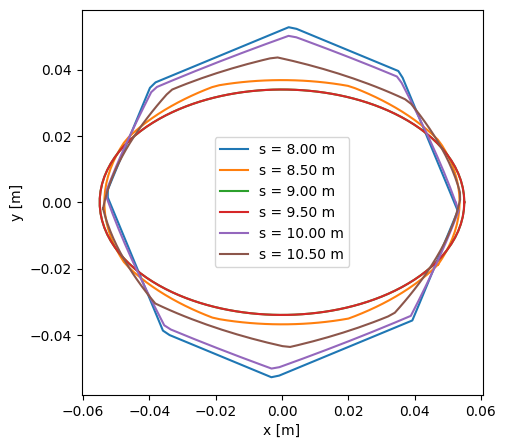

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
for row in sections.rows:
    polygon = row.cross_section
    ax.plot(polygon[:, 0], polygon[:, 1], label=f"s = {row.s:.2f} m")
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend();

At an element, the helper chooses the element entry and exit. If `resolution` is given, it also samples internal cuts. Here we pick `||drift_4`, where the aperture transitions between shapes.


Interpolating profiles: 100%

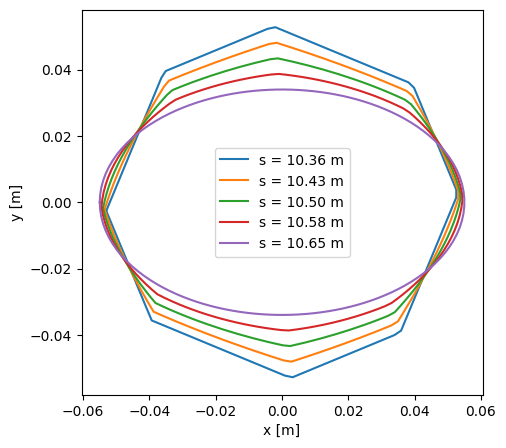

In [5]:
transition_sections = ap.cross_sections_at_element("||drift_4", resolution=0.05, extents=False)
fig, ax = plt.subplots(figsize=(6, 5))
for row in transition_sections.rows:
    polygon = row.cross_section
    ax.plot(polygon[:, 0], polygon[:, 1], label=f"s = {row.s:.2f} m")
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend();

## Beam and halo parameters

To compute the beam envelopes and aperture sigmas the aperture model is combined with:

- local optics and closed-orbit values from Twiss,
- user beam and tolerance parameters in `halo_params`,
- mechanical tolerances attached to the active aperture profile position.

The halo parameters currently configured on the aperture object are:

In [6]:
ap.halo_params

{'emitx_norm': 3.5e-06,
 'emity_norm': 3.5e-06,
 'delta_rms': 0.0,
 'tol_co': 0.0,
 'tol_disp': 0.0,
 'tol_disp_ref': 1.8,
 'tol_disp_ref_beta': 170,
 'tol_beta_beating': 1.0,
 'halo_x': 6.0,
 'halo_y': 6.0,
 'halo_r': 6.0,
 'halo_primary': 6.0}

This is what each of the values means:

- `emitx_norm` ($\varepsilon_{x,\mathrm{n}}$) and `emity_norm` ($\varepsilon_{y,\mathrm{n}}$): normalised emittances;
- `delta_rms` ($\delta_\mathrm{rms}$): RMS relative momentum spread;
- `tol_co` ($r_\mathrm{co}$): closed-orbit uncertainty margin;
- `tol_disp` ($f_D$): dispersion-tolerance scaling factor;
- `tol_disp_ref` ($D_\mathrm{ref}$): reference dispersion error;
- `tol_disp_ref_beta` ($\beta_{D,\mathrm{ref}}$): reference beta for dispersion scaling;
- `tol_beta_beating` ($f_\beta$): beta-beating scaling factor;
- `halo_x`, `halo_y`, `halo_r`, `halo_primary`: define the reference beam racetrack shape through
  $h_x = \mathrm{halo\_x}/\mathrm{halo\_primary}$,
  $h_y = \mathrm{halo\_y}/\mathrm{halo\_primary}$, and
  $h_r = \mathrm{halo\_r}/\mathrm{halo\_primary}$.

For a one-betatron-sigma beam, the optical sizes are

$$
\sigma_x = \sqrt{\frac{\varepsilon_{x,\mathrm{n}}}{\gamma_r\beta_r}\,\beta_x}\; f_\beta,
\qquad
\sigma_y = \sqrt{\frac{\varepsilon_{y,\mathrm{n}}}{\gamma_r\beta_r}\,\beta_y}\; f_\beta.
$$

The envelope calculation builds a racetrack-shaped beam from these one-sigma sizes, scales it by the requested number of sigmas, and adds margins from closed orbit, dispersion tolerance, and aperture-profile tolerances. The dispersion tolerance margins used internally scale like

$$
\Delta x_D = f_\beta f_D D_\mathrm{ref}
\sqrt{\frac{\beta_x}{\beta_{D,\mathrm{ref}}}}\,\delta_\mathrm{rms},
\qquad
\Delta y_D = f_\beta f_D D_\mathrm{ref}
\sqrt{\frac{\beta_y}{\beta_{D,\mathrm{ref}}}}\,\delta_\mathrm{rms}.
$$

Finally, the envelope is shifted by the local closed orbit and by the dispersive orbit shift $(D_x\delta_\mathrm{rms}, D_y\delta_\mathrm{rms})$.

In [7]:
ap.halo_params.update(
    delta_rms=1.0e-4,
    tol_co=1.0e-3,
    tol_disp=1.0,
)
ap.halo_params

{'emitx_norm': 3.5e-06,
 'emity_norm': 3.5e-06,
 'delta_rms': 0.0001,
 'tol_co': 0.001,
 'tol_disp': 1.0,
 'tol_disp_ref': 1.8,
 'tol_disp_ref_beta': 170,
 'tol_beta_beating': 1.0,
 'halo_x': 6.0,
 'halo_y': 6.0,
 'halo_r': 6.0,
 'halo_primary': 6.0}

## Calculating the beam envelopes

The first interface to use is usually the plotting helper. `plot_transverse(sigmas=...)` draws the aperture cross-sections and the beam envelope at a chosen number of sigmas. `middle="beam"` keeps the beam reference at the origin; `middle="aperture"` recentres each cross-section on the aperture.

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

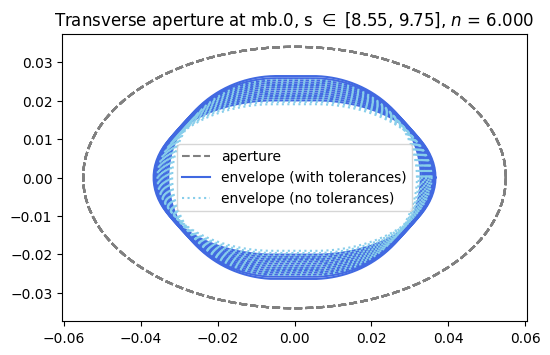

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
ap.plot_transverse("mb.0", resolution=0.1, sigmas=6.0, middle="beam", ax=ax);

The same helper also accepts explicit `s_positions`, which is useful when the points of interest are not tied to a single element.

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

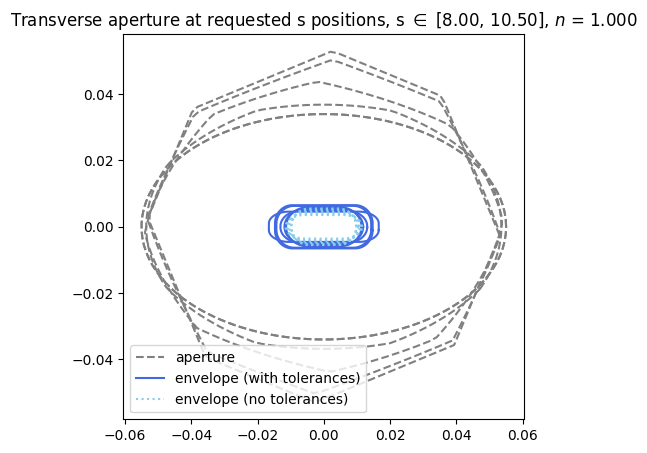

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
ap.plot_transverse(s_positions=sample_s, sigmas=1.0, middle="beam", ax=ax);

For more custom analysis, use `get_envelope_at_s` or `get_envelope_at_element`. These return tables, so we can inspect extents, polygons, and Twiss rows directly, and make our own plots.

In [10]:
envelopes, sliced_twiss = ap.get_envelope_at_s(
    sample_s,
    sigmas=1.0,
    envelopes_num_points=64,
    include_aper_tols=True,
    polygons=True,
    extents=True,
)
envelopes.show(maxwidth='full')

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s  cross_section         min_x         max_x         min_y         max_y
0                                 8 <array(64, 2)>    -0.0165714     0.0165714   -0.00457756    0.00457756
1                               8.5 <array(64, 2)>     -0.013087     0.0130871    -0.0050086     0.0050086
2                                 9 <array(64, 2)>     -0.011876      0.011876   -0.00545438    0.00545438
3                               9.5 <array(64, 2)>    -0.0113799     0.0113799   -0.00589879    0.00589879
4                                10 <array(64, 2)>    -0.0143017     0.0143017   -0.00631585    0.00631585
5                              10.5 <array(64, 2)>    -0.0147398     0.0147398   -0.00652618    0.00652618
Computing beam envelopes: 100%

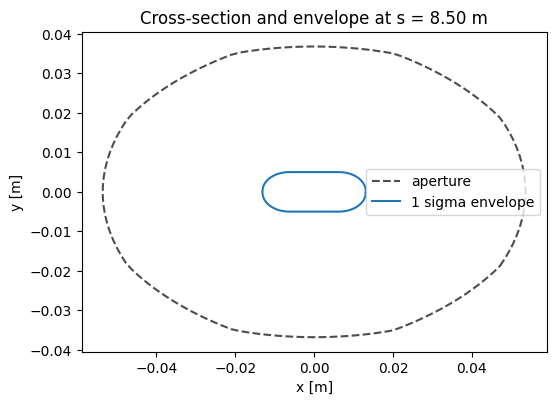

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
row_idx = 1
ap_poly = sections.cross_section[row_idx]
env_poly = envelopes.cross_section[row_idx]
ax.plot(ap_poly[:, 0], ap_poly[:, 1], color="0.3", linestyle="--", label="aperture")
ax.plot(env_poly[:, 0], env_poly[:, 1], color="C0", label="1 sigma envelope")
ax.set_title(f"Cross-section and envelope at s = {sections.s[row_idx]:.2f} m")
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend();

In [12]:
mb_envelopes, mb_twiss = ap.get_envelope_at_element(
    "mb.0",
    sigmas=6.0,
    resolution=0.25,
    envelopes_num_points=64,
    include_aper_tols=True,
    extents=True,
)
mb_envelopes.show(maxwidth='full')

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s  cross_section         min_x         max_x         min_y         max_y
0                           8.54828 <array(64, 2)>    -0.0366663     0.0366663    -0.0200759     0.0200759
1                           8.94943 <array(64, 2)>    -0.0356387     0.0356387    -0.0221719     0.0221719
2                           9.35057 <array(64, 2)>    -0.0343625     0.0343625    -0.0242791     0.0242791
3                           9.75172 <array(64, 2)>    -0.0328479     0.0328479    -0.0263945     0.0263945Computing beam envelopes: 100%


## Computing the maximum aperture sigmas: `n1`

The `get_aperture_sigmas_...` methods compute the largest beam size, in units of the configured halo primary sigma, that fits inside the aperture. This value is usually called `n1`.

There are three algorithms:

- `rays`: fast directional estimate;
- `exact`: more directional sampling from the halo boundary;
- `bisection`: polygon-inside-polygon search (slow but straightforward algorithm).

In general, `rays` is usually the best first choice.

Again, the plotting helper is the quickest entry point. If `sigmas=None`, `plot_transverse` computes the limiting `n1` and plots the corresponding maximum envelope.

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%

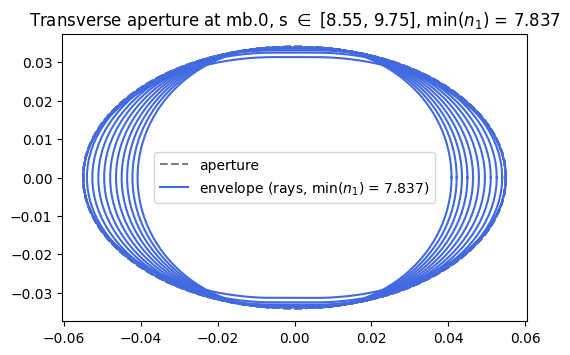

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
ap.plot_transverse("mb.0", resolution=0.1, sigmas=None, method="rays", middle="beam", ax=ax);

For programmatic work, use `get_aperture_sigmas_at_s` or `get_aperture_sigmas_at_element`. You can also request the interpolated aperture and the envelope at the limiting sigma.

If cross section or envelope polygons are not necessary, the `output_...` parameters can be set to false (default), which can speed up the computation for the `rays` and `exact` methods.

In [14]:
n1_at_s, n1_twiss = ap.get_aperture_sigmas_at_s(
    sample_s,
    method="rays",
    num_rays=32,
    output_cross_sections=True,
    output_max_envelopes=True,
)
n1_at_s.show(maxwidth='full')

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s            n1   cross_section       envelope
0                                 8       7.85448 <array(128, 2)> <array(36, 2)>
1                               8.5       9.24387 <array(128, 2)> <array(36, 2)>
2                                 9       9.25219 <array(128, 2)> <array(36, 2)>
3                               9.5       8.26147 <array(128, 2)> <array(36, 2)>
4                                10       9.13604 <array(128, 2)> <array(36, 2)>
5                              10.5       8.40819 <array(128, 2)> <array(36, 2)>
Computing sigmas: 100%

In [15]:
n1_mb, _ = ap.get_aperture_sigmas_at_element(
    "mb.0",
    resolution=0.25,
    method="rays",
    num_rays=32,
)
n1_mb

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 25%

Table: 4 rows, 3 cols
index                             s            n1
0                           8.54828        9.7452
1                           8.94943       9.35882
2                           9.35057       8.53891
3                           9.75172       7.83687

Computing sigmas: 100%

When a Twiss table has already been sampled, use `get_aperture_sigmas_for_twiss` to avoid recomputing optics.

In [16]:
n1_from_existing_twiss = ap.get_aperture_sigmas_for_twiss(
    sliced_twiss=n1_twiss,
    method="rays",
    num_rays=32,
)
n1_from_existing_twiss


Computing sigmas: 100%

Table: 6 rows, 3 cols
index                             s            n1
0                                 8       7.85448
1                               8.5       9.24387
2                                 9       9.25219
3                               9.5       8.26147
4                                10       9.13604
5                              10.5       8.40819

## Horizontal, vertical, and diagonal sigmas

`get_hvd_aperture_sigmas_...` return a table with limiting sigma in three direction families:

- horizontal,
- vertical,
- diagonal at 45 degrees.

This provides more information than `n1`, which does not necessarily help with the directionality.

In [17]:
hvd_table, hvd_twiss = ap.get_hvd_aperture_sigmas_at_s(sample_s)
hvd_table

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%

Table: 6 rows, 6 cols
index                             s n1_horizontal   n1_vertical   n1_diagonal   cross_section
0                                 8       8.01442       18.8045       13.3649 <array(128, 2)>
1                               8.5       9.24387       11.7165       10.5869 <array(128, 2)>
2                                 9       10.1243       9.35962       9.39601 <array(128, 2)>
3                               9.5       10.7102       8.29463       8.92754 <array(128, 2)>
4                                10       9.98077       10.7817       9.89154 <array(128, 2)>
5                              10.5       10.2715       9.04383       9.02562 <array(128, 2)>

In [18]:
hvd_mb, _ = ap.get_hvd_aperture_sigmas_at_element("mb.0", resolution=0.25)
hvd_mb

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 25%

Table: 4 rows, 6 cols
index                             s n1_horizontal   n1_vertical   n1_diagonal   cross_section
0                           8.54828        9.7452       10.5809       10.0815 <array(128, 2)>
1                           8.94943       10.0752       9.48246        9.4594 <array(128, 2)>
2                           9.35057       10.5147       8.58704       9.03879 <array(128, 2)>
3                           9.75172       11.0839       7.84415       8.79223 <array(128, 2)>

Computing sigmas: 100%

## Converting sampled aperture back to `LimitPolygon` elements

The function `get_limit_elements` converts interpolated cross-sections at selected positions into ordinary Xtrack limit elements. This is useful when a calculation needs a conventional element representation rather than the aperture-model object.

In [19]:
limit_elements = ap.get_limit_elements(sample_s[:2])
for s, element in limit_elements.items():
    print(f"s = {s:.3f} m -> {element}")


s = 8.000 m -> LimitPolygon(x_vertices=[ 0.05303722,  0.05205868,  0.05108015,  0.05010161,  0.04912308,
        0.04814454,  0.04716601,  0.04618747,  0.04520894,  0.0442304 ,
        0.04325187,  0.04227333,  0.0412948 ,  0.04031626,  0.03933773,
        0.03835919,  0.03738066,  0.03640212,  0.03509602,  0.03273363,
        0.03037123,  0.02800884,  0.02564645,  0.02328406,  0.02092167,
        0.01855927,  0.01619688,  0.01383449,  0.0114721 ,  0.0091097 ,
        0.00674731,  0.00438492,  0.00202253, -0.00033986, -0.00270226,
       -0.00506465, -0.00742704, -0.00978943, -0.01215183, -0.01451422,
       -0.01687661, -0.019239  , -0.02160139, -0.02396379, -0.02632618,
       -0.02868857, -0.03105096, -0.03341336, -0.03577575, -0.03813814,
       -0.039827  , -0.04080553, -0.04178407, -0.0427626 , -0.04374114,
       -0.04471967, -0.04569821, -0.04667674, -0.04765528, -0.04863381,
       -0.04961235, -0.05059088, -0.05156942, -0.05254795, -0.05254795,
       -0.05156942, -0.0505908

## Longitudinal extent plots

Calling `plot_extents` gives a longitudinal view: aperture extents in black and beam-envelope extents as filled bands. If `sigmas` is not given, the limiting `n1` value for the given `s_positions` will be computed and displayed in the plot. The dashed lines in the plot represent the aperture limitation including the 

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

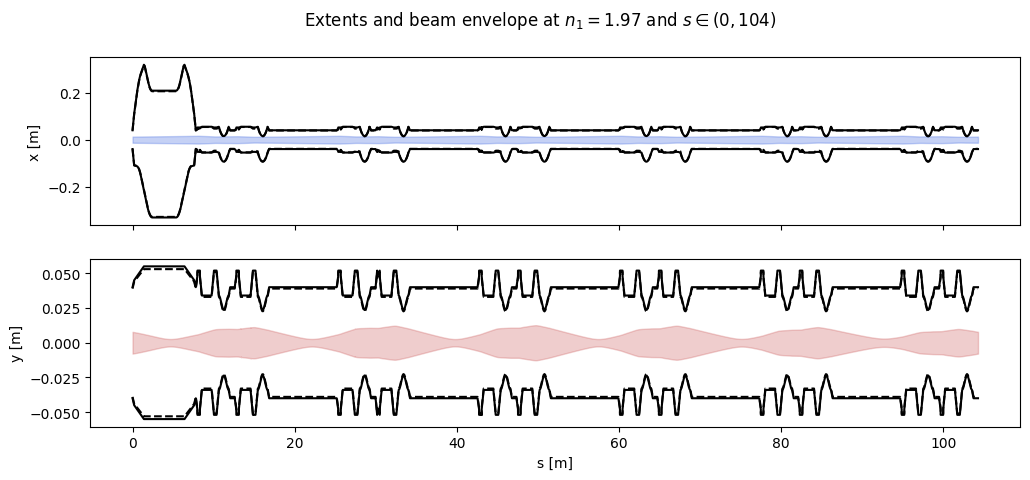

In [20]:
s_sample = aperture.s_around_transitions(resolution=0.1)
aperture.plot_extents(s_positions=s_sample)
plt.gcf().set_figwidth(12);